## Ejercicio: Inventario de productos utilizando Tabla Hash





In [1]:
nombre_estudiante = "Juan José Mican, Alejandro Gil León, Mariana Shenoa Castiblanco, Thaliana Rocio Sierra"
carnet = 1000116549, 1000115165, 1000112473, 1000116534


## 1) Descripción del problema **[1 pts]**
Una tienda necesita mejorar la forma en que consulta los productos de su inventario.

Actualmente tiene muchos productos registrados y recorrer toda una lista cada vez que necesita buscar uno resulta poco eficiente.

Para solucionar este problema se deberá implementar una Tabla Hash, utilizando como llave el código numérico del producto.

Cada producto tendrá:

Código Nombre Precio Cantidad disponible
Por ejemplo:

101 - Arroz       - $4.500 - 20 unidades

205 - Leche       - $3.800  - 15 unidades

312 - Café        - $12.000 - 10 unidades

423 - Pan         - $2.500  - 30 unidades

## 2) Requerimientos **[2 pts]**

### Requerimientos funcionales

- **RF01:** Permitir definir el tamaño `m` de la Tabla Hash.
- **RF02:** Registrar productos con código, nombre, precio y cantidad disponible.
- **RF03:** Calcular la posición de cada producto mediante la función hash `h(código) = código % m`.
- **RF04:** Resolver las colisiones mediante encadenamiento.
- **RF05:** Impedir el registro de dos productos con el mismo código.
- **RF06:** Buscar un producto utilizando primero la función hash.
- **RF07:** Eliminar un producto mediante su código.
- **RF08:** Actualizar la cantidad disponible de un producto.
- **RF09:** Mostrar el contenido completo de la Tabla Hash y evidenciar las colisiones.

### Requerimientos no funcionales

- **RNF01:** Implementar manualmente la Tabla Hash, sin utilizar una estructura `dict` como tabla hash.
- **RNF02:** Desarrollar una solución clara, modular y ejecutable en Jupyter Notebook.
- **RNF03:** Garantizar que la búsqueda, inserción y eliminación aprovechen la posición calculada por la función hash.
- **RNF04:** Mostrar mensajes claros para las operaciones exitosas y cuando los productos no existan.



## 3) Historias de usuario **[3 pts]**

### HU-01. Crear la tabla hash

**Como** encargado de la tienda, **quiero** indicar el tamaño `m` de la tabla para organizar el inventario en `m` posiciones.

**Criterios de aceptación:**

- CA01: La tabla inicia con todas las posiciones en estado "Vacío".
- CA02: La posición de cada producto se calcula mediante `h(código) = código % m`.

### HU-02. Registrar productos

**Como** encargado, **quiero** registrar productos con código, nombre, precio y cantidad disponible para mantener organizado el inventario.

**Criterios de aceptación:**

- CA01: La posición de cada producto se calcula mediante la función hash.
- CA02: No se permiten códigos repetidos.
- CA03: Al terminar el registro, se muestra el estado completo de la tabla.

### HU-03. Manejar colisiones

**Como** encargado, **quiero** que los productos con el mismo índice se almacenen juntos para evitar la pérdida de información.

**Criterios de aceptación:**

- CA01: Las colisiones se resuelven mediante encadenamiento.
- CA02: Una posición puede contener varios productos.
- CA03: Los productos que comparten índice se conservan en la misma cadena.

### HU-04. Buscar un producto

**Como** encargado, **quiero** consultar un producto mediante su código para conocer rápidamente su información.

**Criterios de aceptación:**

- CA01: Se calcula la posición mediante la función hash.
- CA02: La búsqueda se realiza únicamente en la cadena correspondiente.
- CA03: Si el producto existe, se muestran su código, nombre, precio y cantidad disponible.
- CA04: Si no existe, se muestra el mensaje "El producto no está registrado".

### HU-05. Eliminar un producto

**Como** encargado, **quiero** eliminar un producto mediante su código para mantener actualizado el inventario.

**Criterios de aceptación:**

- CA01: Se calcula la posición mediante la función hash.
- CA02: Se elimina únicamente el producto indicado.
- CA03: Los demás productos de la cadena se conservan.
- CA04: Si el producto no existe, se muestra "No se encontró el producto".

### HU-06. Actualizar inventario

**Como** encargado, **quiero** modificar la cantidad disponible de un producto para reflejar las entradas y salidas del inventario.

**Criterios de aceptación:**

- CA01: El producto se busca utilizando la tabla hash.
- CA02: Se muestra la cantidad actual del producto.
- CA03: Se solicita la nueva cantidad disponible.
- CA04: Se confirma la operación con el mensaje "Inventario actualizado correctamente".

### HU-07. Visualizar la tabla hash

**Como** encargado, **quiero** visualizar el contenido completo de la tabla para verificar su estado y las colisiones.

**Criterios de aceptación:**

- CA01: Se muestra cada índice de la tabla.
- CA02: Las posiciones sin productos se muestran como "Vacío".
- CA03: Las posiciones ocupadas muestran todos los productos almacenados en su cadena.


## 4) Diagramas de flujo **[5 pts]**
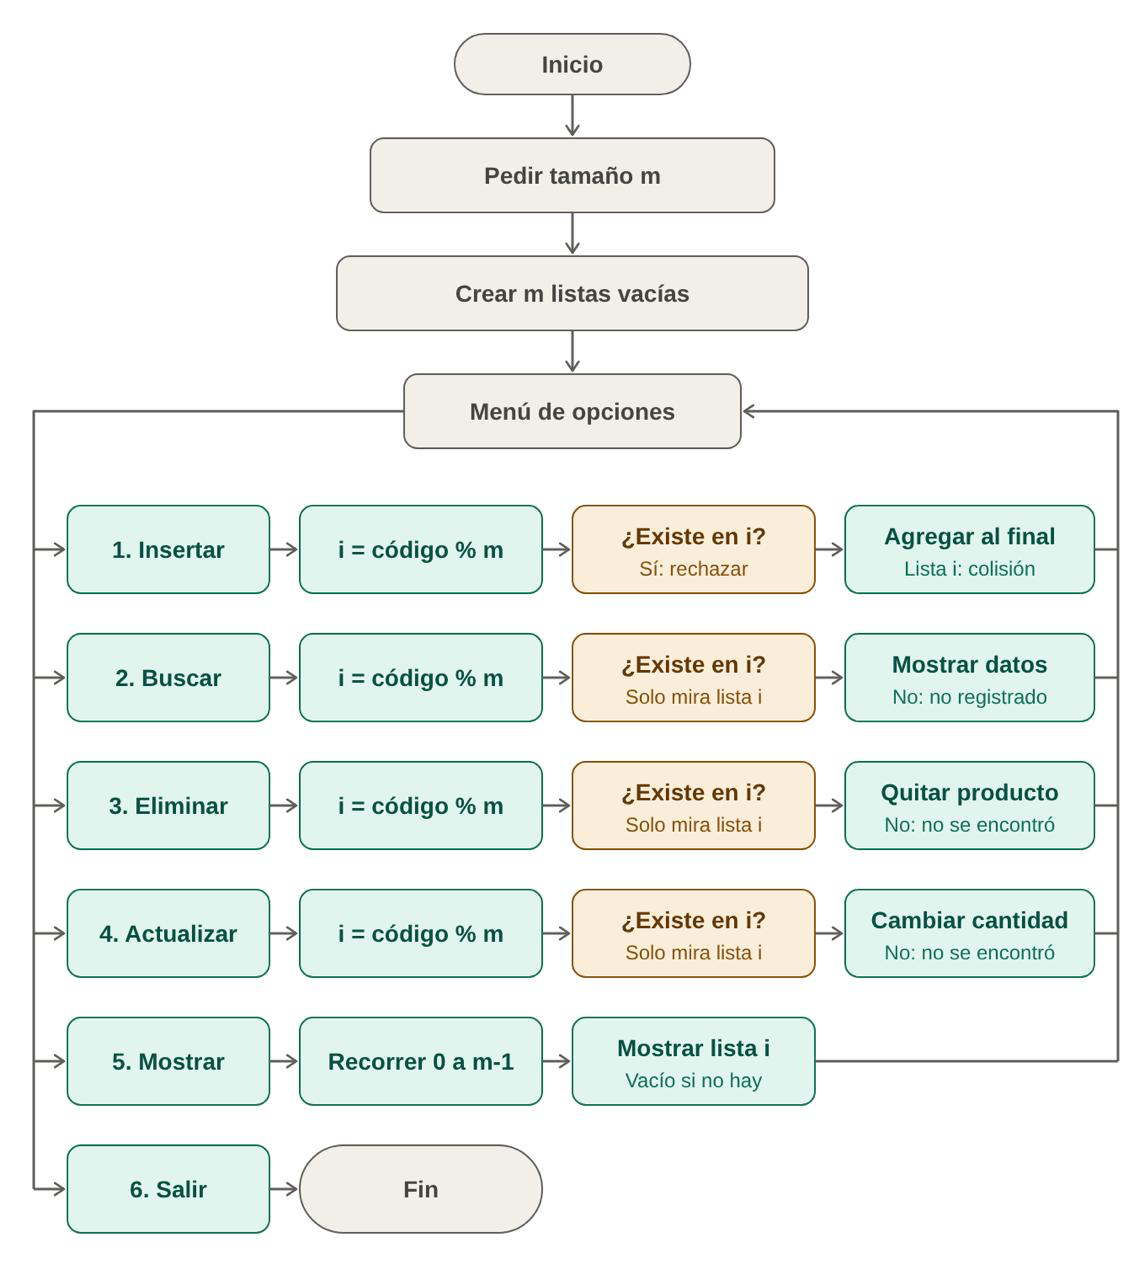


## 5) Análisis de complejidad **[15 pts]**

### Justificación

La función hash `h(código) = código % m` tiene tiempo constante, porque realiza una sola operación aritmética.

Con una buena distribución de códigos, las cadenas de cada posición son cortas y las operaciones de búsqueda, inserción y eliminación tienen un costo promedio cercano a `O(1)`.

Sin embargo, cuando se presentan muchas colisiones, varios productos pueden terminar en una misma posición. En el peor caso, todos los productos quedan en una sola cadena y es necesario recorrerla.

### Función T[n]

Para una búsqueda en una cadena de longitud `k`, podemos modelar el tiempo mediante:

`T(k) = c1 + c2 · k`

Donde:

- `c1` representa el cálculo de la función hash.
- `c2 · k` representa el recorrido de la cadena.

Como `k ≤ n`:

**Mejor caso:**

`k = 1`

`T(n) = c1 + c2`

Complejidad: `Θ(1)`.

**Peor caso:**

`k = n`

`T(n) = c1 + c2 · n`

Complejidad: `Θ(n)`.

La misma idea aplica para la eliminación. En la inserción también se debe verificar que el código no exista previamente, por lo que su costo depende del recorrido de la cadena.

### Gráfica

La siguiente gráfica representa el crecimiento teórico de las operaciones en el mejor y peor caso.

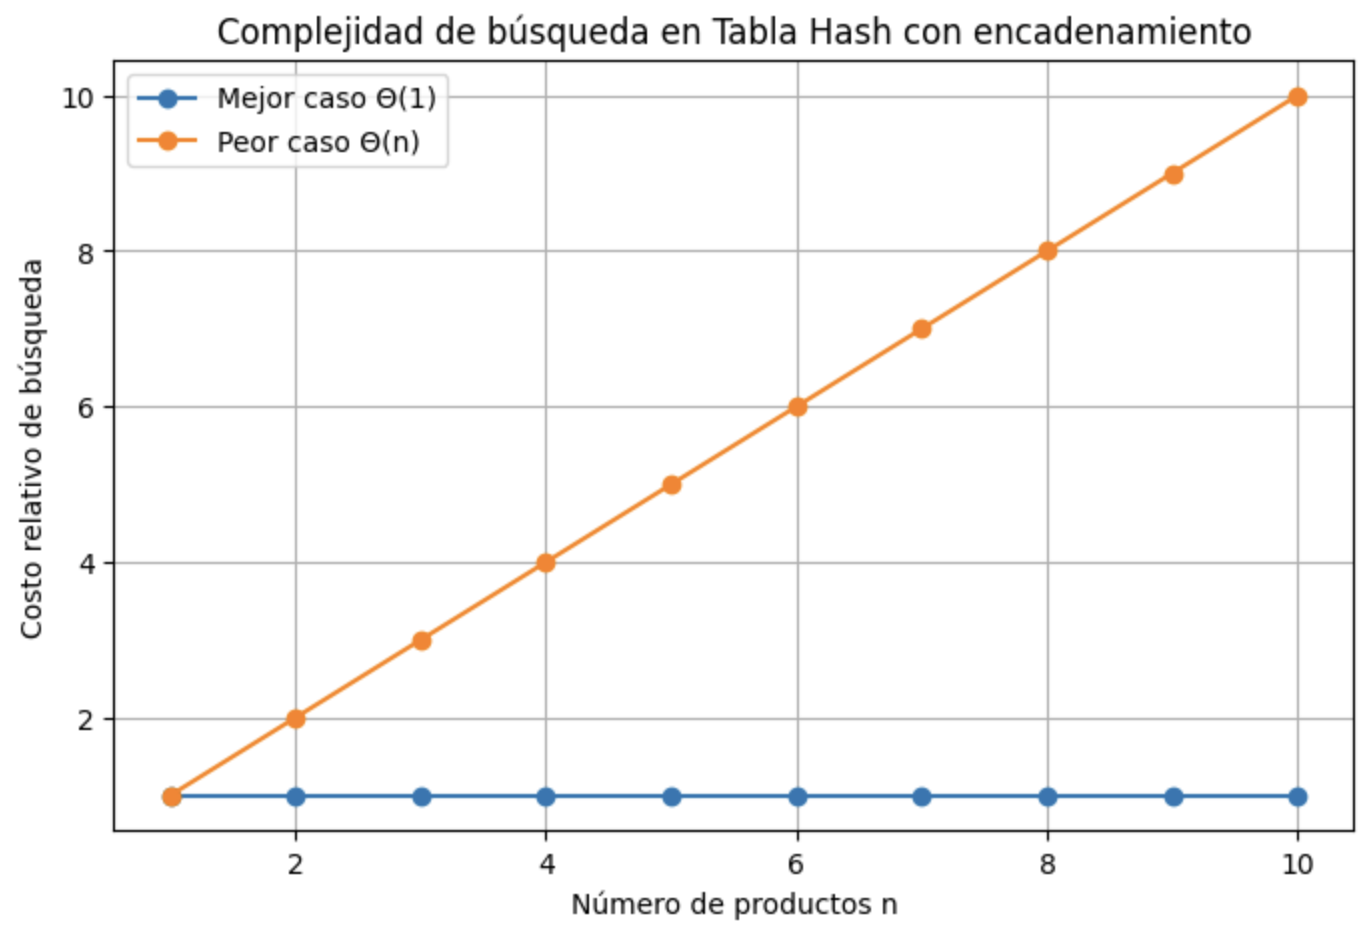

## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


In [2]:
def format_price(price):
    return "$" + f"{price:,}".replace(",", ".")

class Product:
    def __init__(self, code, name, price, quantity):
        self.code = code
        self.name = name
        self.price = price
        self.quantity = quantity

    def __str__(self):
        return f"{self.code} - {self.name}"

    def detail(self):
        return (f"Código: {self.code}\n"
                f"Nombre: {self.name}\n"
                f"Precio: {format_price(self.price)}\n"
                f"Cantidad disponible: {self.quantity}")

class Node:
    def __init__(self, product):
        self.product = product
        self.next = None

class HashTable:

    def __init__(self, m):
        if not isinstance(m, int) or m <= 0:
            raise ValueError("El tamaño m debe ser un entero positivo.")
        self.m = m
        self.table = [None] * m
        self.product_count = 0

    def _hash(self, code):
        return code % self.m

    def insert(self, product):
        index = self._hash(product.code)
        new_node = Node(product)

        if self.table[index] is None:
            self.table[index] = new_node
        else:
            current = self.table[index]
            while True:
                if current.product.code == product.code:
                    return False
                if current.next is None:
                    break
                current = current.next
            current.next = new_node

        self.product_count += 1
        return True

    def search(self, code):
        index = self._hash(code)
        current = self.table[index]
        while current is not None:
            if current.product.code == code:
                return current.product
            current = current.next
        return None

    def delete(self, code):
        index = self._hash(code)
        previous = None
        current = self.table[index]
        while current is not None:
            if current.product.code == code:
                if previous is None:
                    self.table[index] = current.next
                else:
                    previous.next = current.next
                self.product_count -= 1
                return True
            previous = current
            current = current.next
        return False

    def update_quantity(self, code, new_quantity):
        product = self.search(code)
        if product is None:
            return False
        product.quantity = new_quantity
        return True

    def codes_at_index(self, index):
        codes = []
        current = self.table[index]
        while current is not None:
            codes.append(current.product.code)
            current = current.next
        return codes

    def to_text(self):
        lines = ["=" * 40, "TABLA HASH".center(40), "=" * 40]
        for i in range(self.m):
            current = self.table[i]
            if current is None:
                lines.append(f"{i} -> Vacío")
            else:
                prefix = f"{i} -> "
                first = True
                while current is not None:
                    if first:
                        lines.append(prefix + str(current.product))
                        first = False
                    else:
                        lines.append(" " * len(prefix) + str(current.product))
                    current = current.next
        return "\n".join(lines)

    def display(self):
        print(self.to_text())

def read_integer(message, minimum=0):
    while True:
        try:
            value = int(input(message))
            if value < minimum:
                print(f"  Debe ser un número mayor o igual a {minimum}.")
            else:
                return value
        except ValueError:
            print("  Entrada inválida: escribe un número entero (sin puntos ni letras).")


def read_text(message):
    while True:
        text = input(message).strip()
        if text != "":
            return text
        print("  El texto no puede estar vacío.")


def menu():
    table = None

    while True:
        print("\n===== INVENTARIO - TABLA HASH =====")
        print("1. Crear tabla hash")
        print("2. Insertar productos")
        print("3. Buscar producto")
        print("4. Eliminar producto")
        print("5. Actualizar inventario")
        print("6. Mostrar tabla hash")
        print("0. Salir")
        option = input("Elige una opción: ").strip()

        if option == "0":
            print("Hasta luego.")
            break

        elif option == "1":
            m = read_integer("Ingrese el tamaño de la tabla hash: ", minimum=1)
            table = HashTable(m)
            print("Tabla creada (vacía):")
            table.display()

        elif option in ("2", "3", "4", "5", "6") and table is None:
            print("Primero debes crear la tabla (opción 1).")

        elif option == "2":
            n = read_integer("¿Cuántos productos desea registrar?: ", minimum=1)
            for i in range(n):
                print(f"\nProducto {i + 1} de {n}")
                code = read_integer("Código: ", minimum=0)
                name = read_text("Nombre: ")
                price = read_integer("Precio (sin puntos, ej: 4500): ", minimum=0)
                quantity = read_integer("Cantidad: ", minimum=0)
                index = code % table.m
                if table.insert(Product(code, name, price, quantity)):
                    print(f"  {code} % {table.m} = {index} -> guardado en la posición {index}.")
                else:
                    print("  Ya existe un producto con ese código. No se insertó.")
            table.display()

        elif option == "3":
            code = read_integer("Ingrese el código del producto: ", minimum=0)
            product = table.search(code)
            if product is None:
                print("El producto no está registrado.")
            else:
                print("Producto encontrado")
                print(product.detail())

        elif option == "4":
            code = read_integer("Código del producto que desea eliminar: ", minimum=0)
            if table.delete(code):
                print("Producto eliminado correctamente.")
            else:
                print("No se encontró el producto.")

        elif option == "5":
            code = read_integer("Código: ", minimum=0)
            product = table.search(code)
            if product is None:
                print("No se encontró el producto.")
            else:
                print(f"Producto: {product.name} | Cantidad actual: {product.quantity}")
                new_qty = read_integer("Nueva cantidad: ", minimum=0)
                table.update_quantity(code, new_qty)
                print("Inventario actualizado correctamente.")
                print(f"{product.name} - {product.quantity} unidades")

        elif option == "6":
            table.display()

        else:
            print("Opción no válida. Intenta de nuevo.")

## 7) Tests aplicados **[15 pts]**

In [3]:
def create_example_table():
    t = HashTable(7)
    t.insert(Product(101, "Arroz", 4500, 20))
    t.insert(Product(205, "Leche", 3800, 15))
    t.insert(Product(312, "Café", 12000, 10))
    t.insert(Product(108, "Huevos", 16000, 12))
    t.insert(Product(115, "Azúcar", 5000, 8))
    t.insert(Product(302, "Galletas", 3000, 25))
    t.insert(Product(423, "Pan", 2500, 30))
    return t


t = HashTable(7)
assert t.m == 7, "El tamaño debe ser 7"
assert len(t.table) == 7, "La tabla debe tener 7 posiciones"
assert all(pos is None for pos in t.table), "Al inicio todas las posiciones deben estar vacías"
assert t.product_count == 0, "Al inicio no hay productos"
print("✅ Test 1: creación de la tabla")

for bad_m in (0, -3, "7", 2.5):
    try:
        HashTable(bad_m)
        assert False, f"Debió lanzar ValueError con m={bad_m!r}"
    except ValueError:
        pass
print("✅ Test 2: tamaños inválidos rechazados")

t = HashTable(7)
assert t._hash(101) == 3
assert t._hash(108) == 3
assert t._hash(205) == 2
assert t._hash(312) == 4
assert t._hash(302) == 1
assert t._hash(209) == 6
assert t._hash(7) == 0
print("✅ Test 3: función hash")

t = HashTable(7)
assert t.insert(Product(101, "Arroz", 4500, 20)) is True
assert t.product_count == 1
assert t.codes_at_index(3) == [101]
print("✅ Test 4: inserción simple")

t = create_example_table()
assert t.product_count == 7
assert t.codes_at_index(3) == [101, 108, 115, 423], "Los 4 deben encadenarse en el índice 3"
assert t.codes_at_index(2) == [205]
assert t.codes_at_index(0) == [], "El índice 0 debe estar vacío"
print("✅ Test 5: colisiones por encadenamiento")

t = create_example_table()
assert t.insert(Product(108, "Otro", 1, 1)) is False, "108 ya existe"
assert t.product_count == 7, "El contador no debe cambiar"
assert t.search(108).name == "Huevos", "El producto original no debe modificarse"
print("✅ Test 6: códigos repetidos rechazados")

t = create_example_table()
p = t.search(108)
assert p is not None
assert p.name == "Huevos"
assert p.price == 16000
assert p.quantity == 12
assert t.search(101).name == "Arroz"
assert t.search(423).name == "Pan"
print("✅ Test 7: búsqueda exitosa")

t = create_example_table()
assert t.search(122) is None, "122 % 7 = 3 (hay cadena), pero el código no está en ella"
assert t.search(7) is None, "7 % 7 = 0 (posición vacía)"
assert HashTable(5).search(10) is None, "Tabla vacía"
print("✅ Test 8: búsqueda de inexistentes")

t = create_example_table()
assert t.delete(108) is True
assert t.codes_at_index(3) == [101, 115, 423]
assert t.search(108) is None
assert t.product_count == 6

assert t.delete(101) is True
assert t.codes_at_index(3) == [115, 423]

assert t.delete(423) is True
assert t.codes_at_index(3) == [115]

assert t.delete(115) is True
assert t.table[3] is None
assert t.product_count == 3
print("✅ Test 9: eliminación (primero, medio, último, único)")

t = create_example_table()
assert t.delete(999) is False
assert t.product_count == 7, "No debe cambiar nada"
print("✅ Test 10: eliminar inexistente")

t = create_example_table()
assert t.search(101).quantity == 20
assert t.update_quantity(101, 35) is True
assert t.search(101).quantity == 35
assert t.update_quantity(101, 0) is True
assert t.search(101).quantity == 0
assert t.update_quantity(999, 5) is False, "Código inexistente"
print("✅ Test 11: actualización de inventario")

t = HashTable(1)
for code in (10, 20, 30):
    t.insert(Product(code, f"P{code}", 100, 1))
assert t.codes_at_index(0) == [10, 20, 30]
assert t.search(20).name == "P20"
assert t.delete(20) is True
assert t.codes_at_index(0) == [10, 30]
print("✅ Test 12: m = 1")

t = create_example_table()
text = t.to_text()
assert "0 -> Vacío" in text
assert "1 -> 302 - Galletas" in text
assert "3 -> 101 - Arroz" in text
assert "108 - Huevos" in text and "115 - Azúcar" in text, "Deben verse las colisiones"
print("✅ Test 13: visualización de la tabla")

assert format_price(4500) == "$4.500"
assert format_price(12000) == "$12.000"
assert format_price(800) == "$800"
print("✅ Test 14: formato de precio")

print("\nTodas las pruebas pasaron correctamente.")

✅ Test 1: creación de la tabla
✅ Test 2: tamaños inválidos rechazados
✅ Test 3: función hash
✅ Test 4: inserción simple
✅ Test 5: colisiones por encadenamiento
✅ Test 6: códigos repetidos rechazados
✅ Test 7: búsqueda exitosa
✅ Test 8: búsqueda de inexistentes
✅ Test 9: eliminación (primero, medio, último, único)
✅ Test 10: eliminar inexistente
✅ Test 11: actualización de inventario
✅ Test 12: m = 1
✅ Test 13: visualización de la tabla
✅ Test 14: formato de precio

Todas las pruebas pasaron correctamente.


### Main menu

In [ ]:
menu()



===== INVENTARIO - TABLA HASH =====
1. Crear tabla hash
2. Insertar productos
3. Buscar producto
4. Eliminar producto
5. Actualizar inventario
6. Mostrar tabla hash
0. Salir
